# Actividad 1 — Análisis de reseñas de hoteles en Punta Cana

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/meendivil/nlp-vision/blob/main/semana-01/Actividad-01/Actividad_1.ipynb)

Puedes ejecutar este notebook localmente (VS Code / Jupyter) o en **Google Colab**.

Si lo abres en Colab, ejecuta primero la celda **Setup para Google Colab** que aparece abajo: instala las dependencias faltantes, descarga el modelo de spaCy, las stopwords de NLTK y baja el dataset `punta_cana.csv` desde el repositorio. En entornos locales esa celda no hace nada y puedes saltarla.

In [41]:
# === Setup para Google Colab ===
# Esta celda solo hace algo cuando el notebook se ejecuta en Google Colab.
# En entornos locales (VS Code / Jupyter) se ignora y puede saltarse.
import sys
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    # Dependencias adicionales (Colab ya incluye pandas, sklearn, spacy, nltk)
    # gensim ya no viene preinstalado en Colab; sus binarios requieren numpy 1.x y scipy<1.14
    !pip install -q unidecode "gensim==4.3.3" "scipy==1.13.1" "numpy<2"

    # Modelo de spaCy en español
    !python -m spacy download es_core_news_md -q

    # Stopwords de NLTK
    import nltk
    nltk.download("stopwords", quiet=True)

    # Descarga del dataset desde el repositorio de GitHub
    import os, urllib.request
    BASE = "https://raw.githubusercontent.com/meendivil/nlp-vision/main/semana-01/Actividad-01"
    os.makedirs("data", exist_ok=True)
    for archivo in ["punta_cana.csv"]:
        urllib.request.urlretrieve(f"{BASE}/data/{archivo}", f"data/{archivo}")

    print("Setup de Colab completado.")
else:
    print("Entorno local detectado, no se requiere setup adicional.")

Entorno local detectado, no se requiere setup adicional.


In [42]:
# === Carga del dataset ===
import pandas as pd

DATA_PATH = "data/punta_cana.csv"

data = pd.read_csv(DATA_PATH)

print(f"Reseñas: {data.shape[0]:,}  |  Columnas: {data.shape[1]}")
print("Columnas:", list(data.columns))
print("\nValores nulos por columna:")
print(data.isna().sum())

data.head()

Reseñas: 34,561  |  Columnas: 6
Columnas: ['hotel_name', 'location', 'wrote', 'rating', 'title', 'review_text']

Valores nulos por columna:
hotel_name        0
location       4371
wrote            47
rating            0
title             0
review_text       0
dtype: int64


,hotel_name,location,wrote,rating,title,review_text
0,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Vacaciones en El paraíso,El hotel impecable todo muy limpio las habitac...
1,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,HOTEL de la EXCELENCIA,"EXCELENTE, magnífico, excepcional, maravilloso..."
2,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Sentirse como en CASA!!!!!,Tras conocer bastantes hoteles en distintos lu...
3,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,Muy buen nivel,Muy buen hotel. Cumple con todos los requisito...
4,Secrets Cap Cana Resort & Spa,"Villaviciosa, Spain",December 2021,5,10,Excelente todo ....sobre todo el personal. Es ...


In [43]:
# === Etiquetado de sentimiento a partir de la calificación ===
# Criterio estándar en la industria hotelera:
#   - Positivas (4 y 5): experiencia satisfactoria o excelente, alta probabilidad
#     de recomendación.
#   - Negativas (1, 2 y 3): 1 y 2 son claramente experiencias negativas; el 3 se
#     agrupa aquí porque una valoración intermedia evidencia áreas de mejora y no
#     una experiencia plenamente satisfactoria.
# En este dataset la calificación está en la columna "rating" y el texto de la
# reseña en "review_text".

COL_RATING = "rating"
COL_TEXTO = "review_text"

# Filtrado del DataFrame por calificación
positivas = data[data[COL_RATING].isin([4, 5])]
negativas = data[data[COL_RATING].isin([1, 2, 3])]

# Extracción del texto de cada grupo como listas de Python
textos_positivos = positivas[COL_TEXTO].dropna().astype(str).tolist()
textos_negativos = negativas[COL_TEXTO].dropna().astype(str).tolist()

total = len(textos_positivos) + len(textos_negativos)
print(f"Positivas (4-5): {len(textos_positivos):,} ({len(textos_positivos) / total:.1%})")
print(f"Negativas (1-3): {len(textos_negativos):,} ({len(textos_negativos) / total:.1%})")
print(f"Total etiquetado: {total:,} de {len(data):,} reseñas")

print()
print("Distribución por calificación:")
print(data[COL_RATING].value_counts().sort_index().to_string())

print()
print("Ejemplo positivo:", textos_positivos[0][:160], "...")
print("Ejemplo negativo:", textos_negativos[0][:160], "...")

Positivas (4-5): 30,632 (88.6%)
Negativas (1-3): 3,929 (11.4%)
Total etiquetado: 34,561 de 34,561 reseñas

Distribución por calificación:
rating
1     1334
2      900
3     1695
4     3924
5    26708

Ejemplo positivo: El hotel impecable todo muy limpio las habitaciones amplias y con todo tipo de detalles. Las medidas cocid estaban bien ya que en el bufete tú no tocas nada tod ...
Ejemplo negativo: Estuvimos una semana en el Hotel. Habitaciones. Amplias y confortables. Personal. Atento pero forzado en sus palabras y basado en las propinas especialmente del ...


In [44]:
# === Unificación y organización de datos ===
# La etiqueta de sentimiento se deriva directamente de la calificación, con el
# mismo criterio de la celda anterior: 4-5 -> "positiva", 1-3 -> "negativa".
import numpy as np

data["Sentimiento"] = np.where(data[COL_RATING] >= 4, "positiva", "negativa")

# DataFrame final con las dos columnas que pide la actividad.
# Se conserva "data" intacto (con todas sus columnas) para poder volver a
# consultar rating, hotel u origen durante la interpretación de resultados.
df = data[[COL_TEXTO, "Sentimiento"]].rename(columns={COL_TEXTO: "Comentario"})

print("DataFrame final:", df.shape[0], "filas x", df.shape[1], "columnas")
print("Columnas:", list(df.columns))

print()
print("Reseñas por sentimiento:")
print(df["Sentimiento"].value_counts().to_string())

print()
print("Verificación contra las listas de la celda anterior:")
print(f"  positivas: {(df['Sentimiento'] == 'positiva').sum():,}  |  textos_positivos: {len(textos_positivos):,}")
print(f"  negativas: {(df['Sentimiento'] == 'negativa').sum():,}  |  textos_negativos: {len(textos_negativos):,}")

df.head()

DataFrame final: 34561 filas x 2 columnas
Columnas: ['Comentario', 'Sentimiento']

Reseñas por sentimiento:
Sentimiento
positiva    30632
negativa     3929

Verificación contra las listas de la celda anterior:
  positivas: 30,632  |  textos_positivos: 30,632
  negativas: 3,929  |  textos_negativos: 3,929


,Comentario,Sentimiento
0,El hotel impecable todo muy limpio las habitac...,positiva
1,"EXCELENTE, magnífico, excepcional, maravilloso...",positiva
2,Tras conocer bastantes hoteles en distintos lu...,positiva
3,Muy buen hotel. Cumple con todos los requisito...,positiva
4,Excelente todo ....sobre todo el personal. Es ...,positiva


In [45]:
# === Recursos de lenguaje ===
import spacy
import nltk
from nltk.corpus import stopwords
from unidecode import unidecode

# Descargar lista de stopwords de NLTK (solo la primera vez)
nltk.download("stopwords")

# Cargar modelo lingüístico de spaCy en español
nlp = spacy.load("es_core_news_md")

# Stopwords en español y conservación de negaciones.
# "no", "ni" y "tampoco" se retiran de la lista de stopwords porque invierten la
# polaridad de la reseña ("no recomiendo" vs. "recomiendo"): eliminarlas haría
# indistinguibles dos opiniones opuestas.
stopwords_es = set(stopwords.words("spanish"))
neg_keep = {"no", "ni", "tampoco"}
stopwords_es = stopwords_es - neg_keep

print(f"Stopwords en español: {len(stopwords_es)} (negaciones conservadas: {sorted(neg_keep)})")

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\mendi\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Stopwords en español: 311 (negaciones conservadas: ['ni', 'no', 'tampoco'])


In [46]:
import re


def clean_text(texto: str, return_str: bool = False):
    """
    Limpia un texto en español (Latinoamérica) usando spaCy + NLTK stopwords:
    - Tokenización
    - Elimina espacios y signos de puntuación
    - Elimina números (dígitos y cantidades escritas con letra)
    - Elimina stopwords (usando la lista de NLTK, conservando las negaciones)
    - Lematiza las palabras
    - Convierte a minúsculas y quita acentos
    - Separa los restos de puntuación pegados dentro de un token y descarta los
      fragmentos vacíos o que resulten ser stopwords

    Devuelve una lista de tokens limpios o una cadena si return_str=True.
    """
    doc = nlp(texto)
    tokens = []
    for t in doc:
        if t.is_space or t.is_punct or t.like_num:
            continue
        lema = t.lemma_.lower()
        if lema in stopwords_es:
            continue
        # Cuando falta el espacio tras un signo ("limpio.La"), spaCy entrega un solo
        # token: se parte por cualquier carácter que no sea letra o dígito y se vuelve
        # a filtrar cada fragmento (así "limpio.la" queda en "limpio" y se descarta "la").
        for fragmento in re.split(r"[\W_]+", lema):
            if not fragmento or fragmento.isdigit() or fragmento in stopwords_es:
                continue
            tokens.append(unidecode(fragmento))
    return " ".join(tokens) if return_str else tokens

In [47]:
# === Aplicación de la limpieza ===
# Igual que en Tema 2 (data["tokenized_text"] = data["tweet"].apply(clean_text)),
# pero sobre la columna "Comentario" y guardando el resultado en "Tokens".
df["Tokens"] = df["Comentario"].apply(lambda x: clean_text(x))

print("Reseñas tokenizadas:", df["Tokens"].notna().sum())
print("Tokens totales:", int(df["Tokens"].str.len().sum()))
print("Promedio de tokens por reseña:", round(df["Tokens"].str.len().mean(), 1))

df.head()

Reseñas tokenizadas: 34561
Tokens totales: 1402607
Promedio de tokens por reseña: 40.6


,Comentario,Sentimiento,Tokens
0,El hotel impecable todo muy limpio las habitac...,positiva,"[hotel, impecable, limpio, habitacion, amplio,..."
1,"EXCELENTE, magnífico, excepcional, maravilloso...",positiva,"[excelente, magnifico, excepcional, maravillos..."
2,Tras conocer bastantes hoteles en distintos lu...,positiva,"[tras, conocer, bastante, hotel, distinto, lug..."
3,Muy buen hotel. Cumple con todos los requisito...,positiva,"[buen, hotel, cumplir, requisito, descansar, s..."
4,Excelente todo ....sobre todo el personal. Es ...,positiva,"[excelente, personal, ser, diferenciar, resort..."


In [48]:
# === Cálculo de frecuencias por sentimiento ===
from collections import Counter
from itertools import chain

# Separación de los tokens en dos grupos
tokens_positivos = df.loc[df["Sentimiento"] == "positiva", "Tokens"]
tokens_negativos = df.loc[df["Sentimiento"] == "negativa", "Tokens"]

# Aplanado (de lista de listas a una sola secuencia de palabras) y conteo.
# chain.from_iterable evita construir una lista intermedia con ~1.6 M de tokens.
freq_positivas = Counter(chain.from_iterable(tokens_positivos))
freq_negativas = Counter(chain.from_iterable(tokens_negativos))

# Las 50 palabras más frecuentes de cada categoría
top_positivas = freq_positivas.most_common(50)
top_negativas = freq_negativas.most_common(50)

# Totales por grupo: se guardan porque las frecuencias absolutas NO son
# comparables entre categorías (hay ~8 veces más texto positivo que negativo).
total_pos = sum(freq_positivas.values())
total_neg = sum(freq_negativas.values())

print(f"Positivas: {total_pos:,} tokens ({len(freq_positivas):,} términos únicos)")
print(f"Negativas: {total_neg:,} tokens ({len(freq_negativas):,} términos únicos)")

print()
print("Top 50 por categoría")
print(f"{'#':>3}  {'POSITIVAS':<16}{'frec':>9}    {'NEGATIVAS':<16}{'frec':>9}")
print("-" * 62)
for i, ((pal_p, f_p), (pal_n, f_n)) in enumerate(zip(top_positivas, top_negativas), 1):
    print(f"{i:>3}  {pal_p:<16}{f_p:>9,}    {pal_n:<16}{f_n:>9,}")

Positivas: 1,182,081 tokens (35,878 términos únicos)
Negativas: 220,526 tokens (13,634 términos únicos)

Top 50 por categoría
  #  POSITIVAS            frec    NEGATIVAS            frec
--------------------------------------------------------------
  1  ser                57,881    ser                10,370
  2  hotel              26,413    no                  8,685
  3  excelente          19,189    hotel               5,204
  4  buen               16,517    haber               3,824
  5  servicio           15,793    tener               3,726
  6  comida             13,950    habitacion          3,430
  7  no                 13,644    dia                 2,093
  8  haber              13,175    hacer               1,925
  9  atencion           13,074    ir                  1,899
 10  habitacion         11,772    comida              1,806
 11  tener              11,472    servicio            1,799
 12  mejor              10,903    si                  1,507
 13  hacer              10,798 

In [49]:
# === Comparación: términos exclusivos y predominantes ===
# Las frecuencias absolutas NO son comparables entre grupos (hay mucho más texto
# positivo que negativo), por eso se normaliza a apariciones por cada 1,000 tokens.

set_pos = {palabra for palabra, _ in top_positivas}
set_neg = {palabra for palabra, _ in top_negativas}

comunes = set_pos & set_neg
solo_pos = set_pos - set_neg
solo_neg = set_neg - set_pos

print(f"Compartidos por ambos top-50 : {len(comunes)}")
print(f"Exclusivos de POSITIVAS      : {len(solo_pos)}")
print(f"Exclusivos de NEGATIVAS      : {len(solo_neg)}")
print()
print("Exclusivos POSITIVAS:", ", ".join(sorted(solo_pos)))
print()
print("Exclusivos NEGATIVAS:", ", ".join(sorted(solo_neg)))

# Predominancia: cuántas veces más frecuente es un término en un grupo que en el otro.
# El suavizado evita dividir entre cero cuando la palabra falta en una categoría.
SUAVIZADO = 0.01

rel_pos = {p: c / total_pos * 1000 for p, c in freq_positivas.items()}
rel_neg = {p: c / total_neg * 1000 for p, c in freq_negativas.items()}

comparativa = pd.DataFrame({"termino": sorted(set_pos | set_neg)})
comparativa["por_mil_pos"] = comparativa["termino"].map(lambda p: rel_pos.get(p, 0.0))
comparativa["por_mil_neg"] = comparativa["termino"].map(lambda p: rel_neg.get(p, 0.0))
comparativa["razon"] = ((comparativa["por_mil_pos"] + SUAVIZADO)
                        / (comparativa["por_mil_neg"] + SUAVIZADO))
comparativa = comparativa.sort_values("razon", ascending=False)

fmt = lambda x: f"{x:8.2f}"
print()
print("Predominantes en POSITIVAS (razón pos/neg):")
print(comparativa.head(15).to_string(index=False, float_format=fmt))
print()
print("Predominantes en NEGATIVAS (razón pos/neg < 1):")
print(comparativa.tail(15).iloc[::-1].to_string(index=False, float_format=fmt))

Compartidos por ambos top-50 : 30
Exclusivos de POSITIVAS      : 20
Exclusivos de NEGATIVAS      : 20

Exclusivos POSITIVAS: actividad, amable, animacion, atento, bueno, cana, chico, encantar, equipo, especial, excelente, experiencia, familia, gracias, limpio, siempre, super, trato, vacacion, volver

Exclusivos NEGATIVAS: agua, ano, bebida, buffet, deber, decir, dejar, esperar, hora, llegar, mal, malo, mas, mismo, ni, noche, q, recepcion, solo, ver

Predominantes en POSITIVAS (razón pos/neg):
  termino  por_mil_pos  por_mil_neg    razon
 encantar         3.32         0.27    12.01
  gracias         5.66         0.47    11.88
excelente        16.23         1.95     8.27
   equipo         3.33         0.41     7.90
   atento         5.19         0.77     6.66
 especial         4.85         0.73     6.61
    super         5.59         1.08     5.12
    chico         3.25         0.74     4.35
animacion         4.59         1.42     3.22
  siempre         7.34         2.45     2.99
    tra

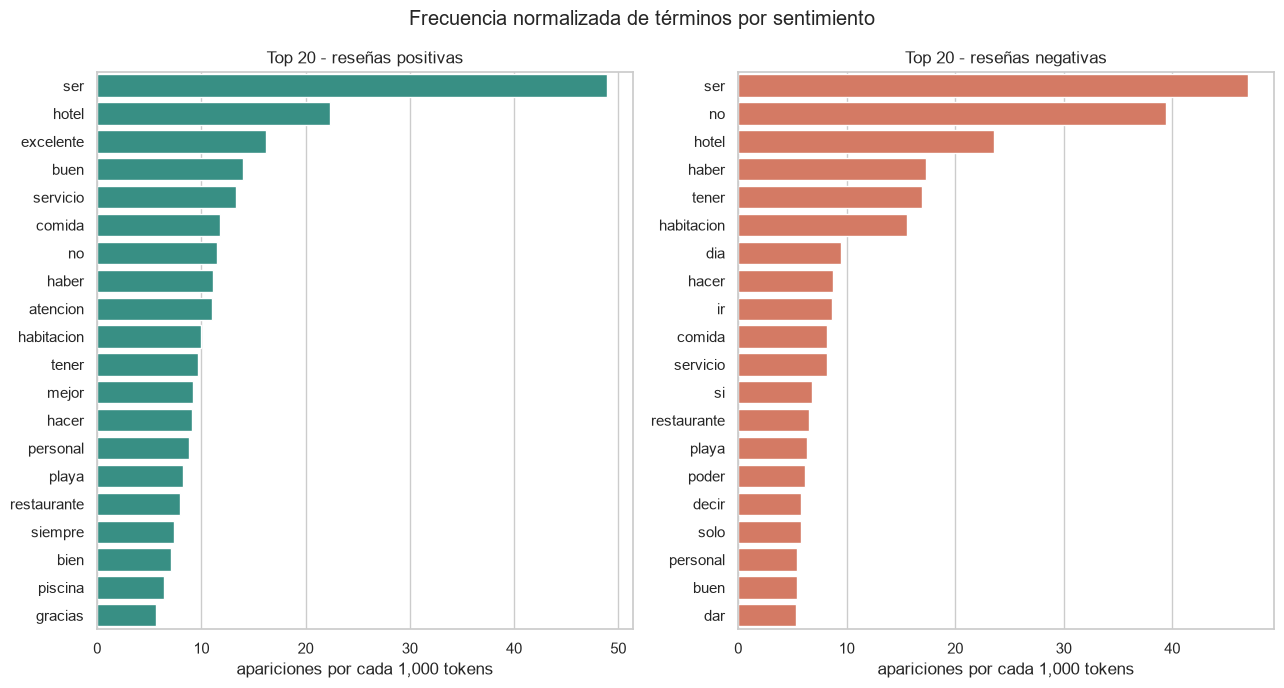

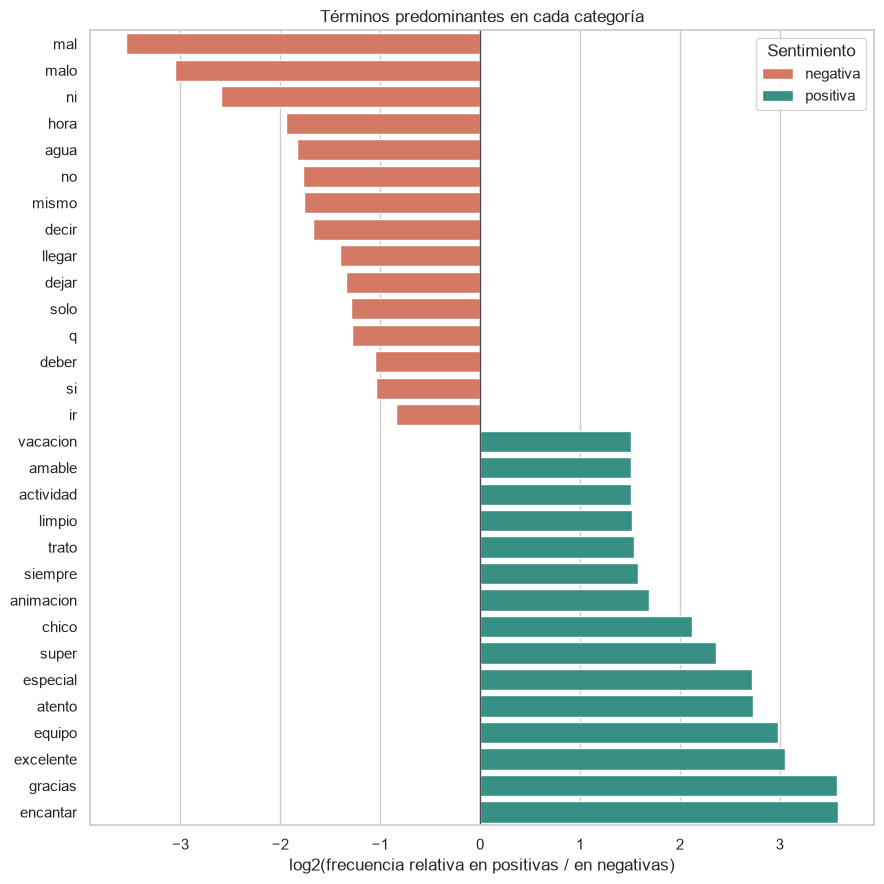

In [50]:
# === Visualización ===
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
TOP_N = 20

# 1) Términos más frecuentes de cada categoría, en frecuencia normalizada
#    (apariciones por cada 1,000 tokens) para que ambos paneles sean comparables.
#    Cada panel se dibuja en su propio eje porque el vocabulario no es el mismo.
fig, axes = plt.subplots(1, 2, figsize=(13, 7))
for ax, (etiqueta, top, total, color) in zip(axes, [
    ("positivas", top_positivas, total_pos, "#2a9d8f"),
    ("negativas", top_negativas, total_neg, "#e76f51"),
]):
    datos = pd.DataFrame({
        "termino": [p for p, _ in top[:TOP_N]],
        "por_mil": [c / total * 1000 for _, c in top[:TOP_N]],
    })
    sns.barplot(data=datos, y="termino", x="por_mil", color=color, ax=ax)
    ax.set_title(f"Top {TOP_N} - reseñas {etiqueta}")
    ax.set_xlabel("apariciones por cada 1,000 tokens")
    ax.set_ylabel("")
fig.suptitle("Frecuencia normalizada de términos por sentimiento")
fig.tight_layout()
plt.show()

# 2) Términos más distintivos: los que predominan claramente en una categoría.
#    Se grafica el logaritmo de la razón para que ambos lados sean simétricos:
#    a la derecha del cero, vocabulario de reseñas positivas; a la izquierda, negativas.
distintivos = pd.concat([comparativa.head(15), comparativa.tail(15)]).copy()
distintivos["log_razon"] = np.log2(distintivos["razon"])
distintivos["Sentimiento"] = np.where(distintivos["log_razon"] > 0, "positiva", "negativa")
distintivos = distintivos.sort_values("log_razon")

plt.figure(figsize=(9, 9))
sns.barplot(data=distintivos, y="termino", x="log_razon", hue="Sentimiento",
            palette={"positiva": "#2a9d8f", "negativa": "#e76f51"}, dodge=False)
plt.axvline(0, color="0.3", linewidth=1)
plt.xlabel("log2(frecuencia relativa en positivas / en negativas)")
plt.ylabel("")
plt.title("Términos predominantes en cada categoría")
plt.tight_layout()
plt.show()

In [51]:
# === Impacto de las decisiones de limpieza ===
# Cada variante reprocesa el texto cambiando una decisión a la vez. Se evalúa sobre
# una muestra estratificada porque recorrer el corpus completo por cada variante
# tardaría varios minutos.
N_MUESTRA = 400  # reseñas por clase

muestra = pd.concat([
    df[df["Sentimiento"] == s].sample(N_MUESTRA, random_state=42)
    for s in ("positiva", "negativa")
])

# Verbos de alta frecuencia y bajo contenido semántico que sobreviven a la
# lematización (sus formas conjugadas no están en la lista de NLTK).
AUXILIARES = {"ser", "estar", "haber", "tener", "poder", "hacer", "ir", "dar", "deber"}

def variante(texto, quitar_stopwords=True, conservar_negaciones=True,
             lematizar=True, quitar_numeros=True, quitar_auxiliares=False):
    """Versión parametrizable de clean_text para medir el efecto de cada decisión."""
    lista_stop = stopwords_es if conservar_negaciones else stopwords_es | neg_keep
    salida = []
    for t in nlp(texto):
        if t.is_space or t.is_punct:
            continue
        if quitar_numeros and t.like_num:
            continue
        palabra = t.lemma_.lower() if lematizar else t.text.lower()
        if quitar_stopwords and palabra in lista_stop:
            continue
        if quitar_auxiliares and palabra in AUXILIARES:
            continue
        salida.append(unidecode(palabra))
    return salida

VARIANTES = {
    "base (la del notebook)": {},
    "sin quitar stopwords": {"quitar_stopwords": False},
    "negaciones eliminadas": {"conservar_negaciones": False},
    "sin lematizar": {"lematizar": False},
    "sin verbos auxiliares": {"quitar_auxiliares": True},
}

resultados = {}
for nombre, opciones in VARIANTES.items():
    conteos = {}
    for etiqueta in ("positiva", "negativa"):
        textos = muestra.loc[muestra["Sentimiento"] == etiqueta, "Comentario"]
        conteos[etiqueta] = Counter(chain.from_iterable(variante(t, **opciones) for t in textos))
    resultados[nombre] = conteos
    top10 = ", ".join(p for p, _ in conteos["negativa"].most_common(10))
    print(f"{nombre:<24} | vocabulario: {len(conteos['negativa']):>5,} | top-10 negativas: {top10}")

print()
print("Posición del token 'no' en el ranking de reseñas negativas:")
for nombre, conteos in resultados.items():
    ranking = [p for p, _ in conteos["negativa"].most_common()]
    posicion = "#" + str(ranking.index("no") + 1) if "no" in ranking else "eliminado"
    print(f"  {nombre:<24} -> {posicion}")

base (la del notebook)   | vocabulario: 4,161 | top-10 negativas: ser, no, hotel, habitacion, haber, tener, dia, hacer, ir, playa
sin quitar stopwords     | vocabulario: 4,232 | top-10 negativas: el, de, que, y, en, ser, no, uno, a, yo
negaciones eliminadas    | vocabulario: 4,158 | top-10 negativas: ser, hotel, habitacion, haber, tener, dia, hacer, ir, playa, servicio
sin lematizar            | vocabulario: 5,543 | top-10 negativas: no, hotel, habitacion, si, servicio, habitaciones, playa, bien, comida, dia
sin verbos auxiliares    | vocabulario: 4,154 | top-10 negativas: no, hotel, habitacion, dia, playa, servicio, comida, si, bien, restaurante

Posición del token 'no' en el ranking de reseñas negativas:
  base (la del notebook)   -> #2
  sin quitar stopwords     -> #7
  negaciones eliminadas    -> eliminado
  sin lematizar            -> #1
  sin verbos auxiliares    -> #1


In [52]:
# === Bag of Words: matriz documento-término ===
from sklearn.feature_extraction.text import CountVectorizer

# La columna "Tokens" ya viene tokenizada, sin stopwords y lematizada, así que se
# le indica al vectorizador que NO vuelva a procesar el texto: el analizador de
# identidad recibe la lista de tokens y la devuelve tal cual.
# min_df=5 descarta los términos que aparecen en menos de 5 reseñas (cola de ruido:
# erratas, nombres propios sueltos).
identidad = lambda tokens: tokens

bow_vectorizer = CountVectorizer(analyzer=identidad, min_df=5)
X_bow = bow_vectorizer.fit_transform(df["Tokens"])
vocabulario = bow_vectorizer.get_feature_names_out()

vocab_sin_filtro = len(set(chain.from_iterable(df["Tokens"])))
densidad = X_bow.nnz / (X_bow.shape[0] * X_bow.shape[1])

print(f"Matriz documento-término: {X_bow.shape[0]:,} documentos x {X_bow.shape[1]:,} términos")
print(f"Vocabulario: {len(vocabulario):,} términos (de {vocab_sin_filtro:,} sin el filtro min_df)")
print(f"Celdas distintas de cero: {X_bow.nnz:,} ({densidad:.3%} de la matriz)")
print("La matriz se mantiene dispersa: en denso ocuparía",
      f"{X_bow.shape[0] * X_bow.shape[1] * 8 / 1e9:.1f} GB.")

# Términos más frecuentes en todo el corpus según la matriz
conteos = np.asarray(X_bow.sum(axis=0)).ravel()
orden_bow = conteos.argsort()[::-1]

print()
print("Top 10 por conteo (Bag of Words):")
for i in orden_bow[:10]:
    print(f"  {vocabulario[i]:<15} {conteos[i]:>8,}")

# Vista de un recorte de la matriz (solo se densifica lo que se va a mostrar)
top8 = orden_bow[:8]
vista = pd.DataFrame(X_bow[:5].toarray()[:, top8], columns=vocabulario[top8])
vista.insert(0, "Sentimiento", df["Sentimiento"].head(5).values)
vista

Matriz documento-término: 34,561 documentos x 9,766 términos
Vocabulario: 9,766 términos (de 40,235 sin el filtro min_df)
Celdas distintas de cero: 1,164,895 (0.345% de la matriz)
La matriz se mantiene dispersa: en denso ocuparía 2.7 GB.

Top 10 por conteo (Bag of Words):
  ser               68,251
  hotel             31,617
  no                22,329
  excelente         19,620
  buen              17,704
  servicio          17,592
  haber             16,999
  comida            15,756
  habitacion        15,202
  tener             15,198


,Sentimiento,ser,hotel,no,excelente,buen,servicio,haber,comida
0,positiva,2,1,2,0,0,0,1,0
1,positiva,1,3,1,1,0,0,3,0
2,positiva,6,2,0,0,0,3,0,0
3,positiva,3,1,0,1,1,0,1,0
4,positiva,4,0,0,1,0,0,0,0


In [53]:
# === TF-IDF: ponderación por rareza ===
from sklearn.feature_extraction.text import TfidfVectorizer

# Mismo vocabulario que BoW, pero cada conteo se pondera a la baja según en cuántos
# documentos aparece el término (idf): lo que sale en todas las reseñas pesa poco.
tfidf_vectorizer = TfidfVectorizer(analyzer=identidad, min_df=5)
X_tfidf = tfidf_vectorizer.fit_transform(df["Tokens"])
terminos = tfidf_vectorizer.get_feature_names_out()

print(f"Matriz TF-IDF: {X_tfidf.shape[0]:,} x {X_tfidf.shape[1]:,}")

# Términos con mayor peso DENTRO de un documento concreto
def terminos_con_mayor_peso(posicion, n=8):
    fila = X_tfidf[posicion]
    pares = sorted(zip(fila.indices, fila.data), key=lambda par: -par[1])[:n]
    return [(terminos[i], round(float(peso), 3)) for i, peso in pares]

for etiqueta in ("positiva", "negativa"):
    posicion = int(np.where(df["Sentimiento"].values == etiqueta)[0][0])
    print()
    print(f"--- Reseña {etiqueta} (fila {posicion}) ---")
    print(df["Comentario"].iloc[posicion][:200], "...")
    print("Términos con mayor peso:")
    for termino, peso in terminos_con_mayor_peso(posicion):
        print(f"  {termino:<15} {peso:.3f}")

# Contraste global: qué sube y qué baja al ponderar por idf
peso_medio = np.asarray(X_tfidf.mean(axis=0)).ravel()
orden_tfidf = peso_medio.argsort()[::-1]

print()
print(f"{'Top 10 por CONTEO (BoW)':<32}{'Top 10 por PESO MEDIO (TF-IDF)'}")
for i, j in zip(orden_bow[:10], orden_tfidf[:10]):
    print(f"  {vocabulario[i]:<14}{conteos[i]:>8,}        {terminos[j]:<14}{peso_medio[j]:>8.4f}")

Matriz TF-IDF: 34,561 x 9,766

--- Reseña positiva (fila 0) ---
El hotel impecable todo muy limpio las habitaciones amplias y con todo tipo de detalles. Las medidas cocid estaban bien ya que en el bufete tú no tocas nada todo te lo sirven ellos . En la piscina y e ...
Términos con mayor peso:
  bufete          0.296
  servir          0.251
  fidelina        0.230
  divierta        0.230
  pases           0.220
  barbacoa        0.209
  bomba           0.205
  desinfectar     0.203

--- Reseña negativa (fila 7) ---
Estuvimos una semana en el Hotel. Habitaciones. Amplias y confortables. Personal. Atento pero forzado en sus palabras y basado en las propinas especialmente del turista americano Comida. Mucha de ella ...
Términos con mayor peso:
  americano       0.414
  turismo         0.288
  tipo            0.195
  advisor         0.193
  forzado         0.190
  basado          0.183
  clientela       0.183
  mucha           0.181

Top 10 por CONTEO (BoW)         Top 10 por PESO MEDIO (TF

In [54]:
# =========================
# Entrenamiento Word2Vec
# =========================
# Misma configuración que en Tema 2.
# Opción principal: Skip-gram (sg=1) suele capturar mejor palabras raras/relaciones semánticas
from gensim.models import Word2Vec

w2v = Word2Vec(
    sentences=df["Tokens"].to_list(),
    vector_size=70,   # 100-300 es común
    window=2,         # contexto
    min_count=2,      # ignora palabras raras (<2 ocurrencias)
    workers=8,
    sg=1,             # 1=Skip-gram, 0=CBOW
    negative=10,      # negative sampling
    epochs=50,
    seed=42,
)

print(f"Vocabulario de Word2Vec: {len(w2v.wv.key_to_index):,} términos")
print(f"Dimensión de cada vector: {w2v.wv.vector_size}")

Vocabulario de Word2Vec: 19,373 términos
Dimensión de cada vector: 70


In [55]:
# =========================
# Consultas de ejemplo con Word2Vec
# =========================
def show_similares(model, palabra, topn=10):
    if palabra in model.wv.key_to_index.keys():
        print(f"\nPalabras más similares a '{palabra}':")
        for w, s in model.wv.most_similar(palabra, topn=topn):
            print(f"  {w:15s} {s:.4f}")
    else:
        print(f"\n'{palabra}' no está en el vocabulario.")

# Similitud de palabras del dominio hotelero
for palabra in ["habitacion", "limpio", "playa", "excelente", "pesimo"]:
    show_similares(w2v, palabra, topn=5)


Palabras más similares a 'habitacion':
  habiatacion     0.7208
  habitaccion     0.7175
  nuevisimo       0.7149
  sumamemte       0.7114
  oloroso         0.6977

Palabras más similares a 'limpio':
  limpia          0.7428
  superrrr        0.7210
  amolia          0.7180
  nuevisimo       0.7152
  encabto         0.7099

Palabras más similares a 'playa':
  geografico      0.7392
  500mts          0.7240
  mar             0.7183
  piscina         0.7166
  pileta          0.7101

Palabras más similares a 'excelente':
  buen            0.8914
  exelente        0.7896
  espectacular    0.7879
  excepcional     0.7747
  immejorable     0.7718

Palabras más similares a 'pesimo':
  malo            0.7986
  horrible        0.7569
  fatal           0.7510
  desastre        0.7131
  pesima          0.7096


## Comparación de resultados

### ¿Qué diferencias observas entre bag of words y TF-IDF?
Como vimos en clase, Bag of Words principalmente cuenta cuántas veces aparece cada palabra, mientras que TF-IDF además considera qué tan relevante es esa palabra dentro de una reseña. En los resultados se puede observar que Bag of Words da mayor importancia a palabras muy frecuentes como ser o hotel, mientras que TF-IDF permite resaltar palabras más particulares de cada reseña.


### ¿Qué ventajas tiene Word2Vec frente a los métodos anteriores?

Como vimos en clase, una ventaja de Word2Vec es que permite identificar relaciones entre palabras de acuerdo con el contexto donde aparecen. Esto se observa en los resultados, por ejemplo, excelente aparece relacionado con buen y espectacular, mientras que pesimo se relaciona con malo, horrible y terrible.

### ¿Qué técnica representa de mejor manera el significado del texto y por qué?

Considero que Word2Vec representa de mejor manera el significado, ya que no solamente toma en cuenta la frecuencia de las palabras, sino también las relaciones que existen entre ellas según su contexto. Los resultados permiten observar que palabras con significados similares terminan teniendo representaciones cercanas.

## Reflexión final

### ¿Cómo impacta la calidad del texto en los resultados del análisis?
La calidad del texto impacta directamente en los resultados, ya que errores, ruido o palabras innecesarias pueden generar representaciones menos precisas. Una buena limpieza ayuda a conservar la información más relevante para el análisis.

### ¿Qué errores en el preprocesamiento podrían afectar el desempeño de un modelo de NLP?
Uno de los principales errores sería eliminar información importante durante la limpieza, por ejemplo las negaciones. Palabras como no, ni o tampoco pueden cambiar completamente el significado de una reseña, por lo que eliminarlas afectaría los resultados.

### ¿Qué estrategias utilizarías para escalar la solución a entornos reales con grandes volúmenes de datos?
Utilizaría procesamiento por partes, paralelización y, cuando el modelo lo permita, procesamiento con GPU para reducir los tiempos de entrenamiento y análisis. También podría trabajar con muestras representativas cuando no sea necesario procesar todo el corpus al mismo tiempo.